In [3]:
%pip install missingno matplotlib numpy pandas seaborn

import re
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

# Настройка стиля отображения графиков
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

print("Библиотеки успешно импортированы!")

Note: you may need to restart the kernel to use updated packages.
Библиотеки успешно импортированы!


In [4]:
import os

# Проверяем, загружен ли уже файл, чтобы не запрашивать повторно при перезапуске ячейки
if not os.path.exists("data_example.csv"):
    print("Внимание: Файл 'data_example.csv' не найден в папке проекта!")
    print("Пожалуйста, скопируйте файл 'data_example.csv' в папку:", os.getcwd())
else:
    print("Файл 'data_example.csv' успешно найден в папке проекта.")

Файл 'data_example.csv' успешно найден в папке проекта.


In [5]:
# 1-2. Чтение датасета с пропуском служебных строк и обработкой аномалий
df = pd.read_csv(
    "data_example.csv",
    skiprows=[0, 2, 3, 4],  # убираем строку выгрузки и строки Units/Digital/Rate
    encoding="utf-8",
    encoding_errors="ignore",  # защита от первого невалидного байта 0xb9
    sep=",",
    low_memory=False,  # предотвращает DtypeWarning
    na_values=["-", "", " ", "Missing", "Offln"],  # текстовые статусы в NaN
)


# 3. Функция очистки названий колонок: оставляем только устройство и параметр
def clean_col_name(col):
  if col.startswith("Name") or col.startswith("Unnamed"):
    return "timestamp"
  match = re.match(r"^\s*([0-9A-Za-z]+).*?:\s*(?:---\s*)?(.*)$", col)
  if match:
    return f"{match.group(1)}: {match.group(2).strip()}"
  return col.strip()


df.columns = [clean_col_name(c) for c in df.columns]

# Преобразуем числовые признаки к float (исключая временную шкалу)
for col in df.columns:
  if col != "timestamp":
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Размерность датасета после загрузки:", df.shape)
print("Примеры очищенных названий колонок:\n", df.columns[:8].tolist())

Размерность датасета после загрузки: (26151, 96)
Примеры очищенных названий колонок:
 ['timestamp', '10CT: EKC состояние', '10CT: u09 S5 Темп', '11CT: u69 Sair Темп', '11CT: u09 S5 Темп', '11CT: EKC состояние', '12CT: u09 S5 Темп', '12CT: u69 Sair Темп']


In [6]:
# 4. Вывод информации о структуре
print("Общая информация о датафрейме:")
df.info(verbose=False, memory_usage="deep")

Общая информация о датафрейме:
<class 'pandas.DataFrame'>
RangeIndex: 26151 entries, 0 to 26150
Columns: 96 entries, timestamp to 111CT: Cond Reference
dtypes: float64(95), str(1)
memory usage: 19.7 MB


In [7]:
# 5. Приведение времени к DatetimeIndex и сортировка
df["timestamp"] = pd.to_datetime(
    df["timestamp"].str.strip(), format="%H:%M:%S %d/%m/%Y"
)
df = df.set_index("timestamp").sort_index()

print("Минимальная дата:", df.index.min())
print("Максимальная дата:", df.index.max())
print("\nПервые 3 строки датасета:")
display(df.head(3))

Минимальная дата: 2021-03-01 00:00:00
Максимальная дата: 2021-04-06 07:40:00

Первые 3 строки датасета:


,10CT: EKC состояние,10CT: u09 S5 Темп,11CT: u69 Sair Темп,11CT: u09 S5 Темп,11CT: EKC состояние,12CT: u09 S5 Темп,12CT: u69 Sair Темп,12CT: EKC состояние,13CT: u69 Sair Темп,13CT: EKC состояние,...,111CT: Comp 2A Status,111CT: Comp 3A Status,111CT: Comp 1A Status,111CT: Comp A Reference,111CT: Comp A Capacity,111CT: Cond Requested Cap,111CT: Cond Running Cap,111CT: Cond Ctrl Pressure,111CT: Sc3 Датч нар воздуха,111CT: Cond Reference
timestamp,,,,,,,,,,,,,,,,,,,,,
2021-03-01 00:00:00,0.0,-11.39,7.50,9.11,11.0,-9.39,0.22,11.0,1.78,0.0,...,1.0,1.0,3.0,0.6,38.0,0.0,0.0,8.68,-8.22,14.77
2021-03-01 00:02:00,11.0,-14.78,7.78,9.11,11.0,-1.39,1.72,11.0,-0.78,11.0,...,1.0,3.0,3.0,0.6,59.0,0.0,0.0,8.59,-8.22,14.77
2021-03-01 00:04:00,11.0,-1.50,7.78,9.11,11.0,2.00,3.11,11.0,-1.28,11.0,...,3.0,3.0,3.0,0.6,81.0,0.0,0.0,10.76,-8.22,14.77


Топ-10 колонок с наибольшим числом пропусков:


Gazoanalyzator: Gas Level %      10
Gazoanalyzator: Gas Level Ppm    10
20CT: EKC состояние               9
20CT: u69 Sair Темп               9
20CT: u09 S5 Темп                 9
11CT: u09 S5 Темп                 8
13CT: u09 S5 Темп                 8
13CT: EKC состояние               8
13CT: u69 Sair Темп               8
16CT: u09 S5 Темп                 8
dtype: int64

<Figure size 1400x500 with 0 Axes>

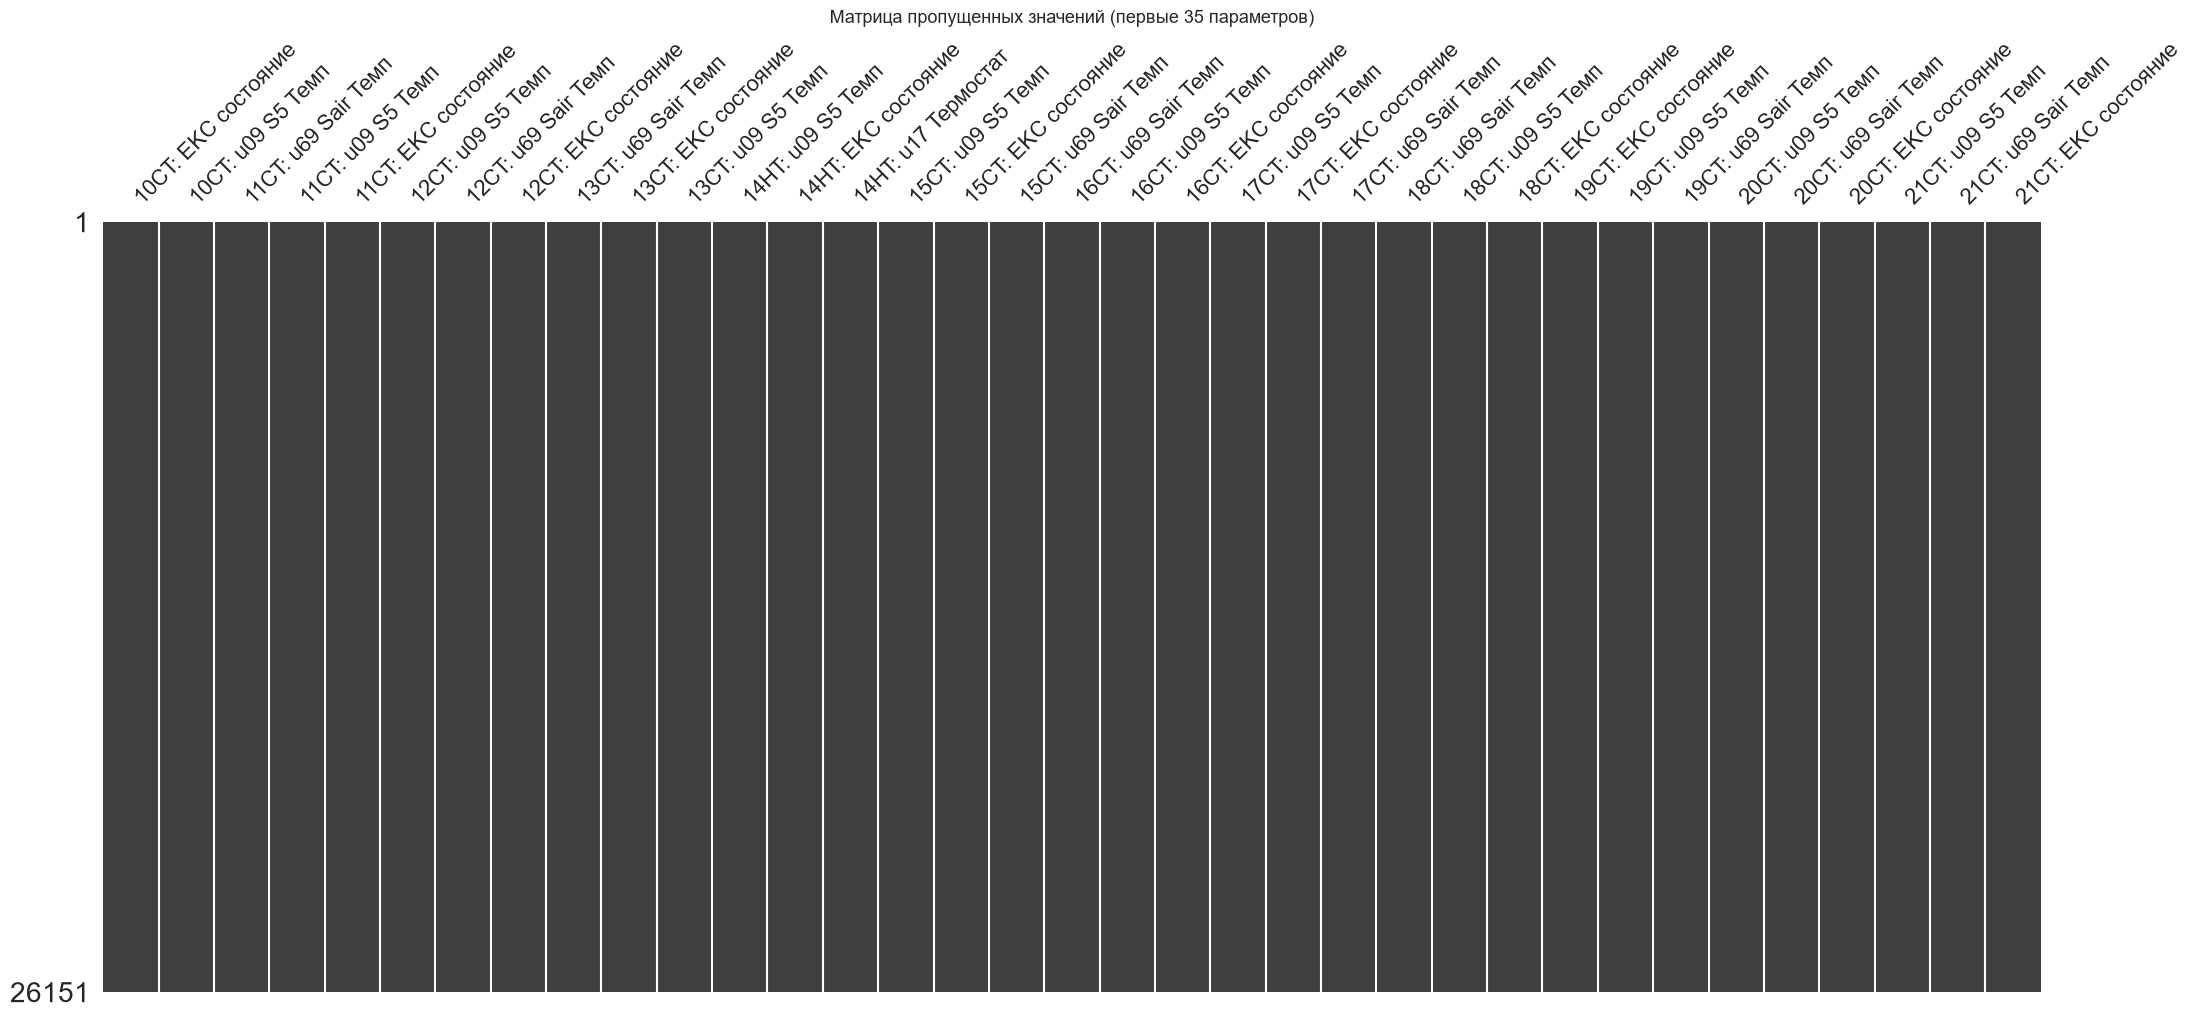

In [8]:
# 6. Подсчет пропусков
null_counts = df.isna().sum()
print("Топ-10 колонок с наибольшим числом пропусков:")
display(null_counts[null_counts > 0].sort_values(ascending=False).head(10))

# Визуализация матрицы пропусков
plt.figure(figsize=(14, 5))
msno.matrix(df.iloc[:, :35], sparkline=False)
plt.title(
    "Матрица пропущенных значений (первые 35 параметров)", fontsize=13, pad=12
)
plt.show()

In [9]:
# 7. Оптимизация типов данных
df_opt = df.copy()
mem_before = df.memory_usage(deep=True).sum() / (1024**2)

for col in df_opt.columns:
  unique_vals = df_opt[col].nunique(dropna=True)
  if unique_vals <= 10:
    df_opt[col] = df_opt[col].astype("category")
  else:
    df_opt[col] = pd.to_numeric(df_opt[col], downcast="float")

mem_after = df_opt.memory_usage(deep=True).sum() / (1024**2)

print(f"Размер до оптимизации:    {mem_before:.2f} МБ")
print(f"Размер после оптимизации: {mem_after:.2f} МБ")
print(
    f"Экономия памяти:          {((mem_before - mem_after) / mem_before) * 100:.2f}%"
)

Размер до оптимизации:    19.15 МБ
Размер после оптимизации: 7.28 МБ
Экономия памяти:          61.97%


Найденные колонки: ['21CT: u69 Sair Темп', '22CT: u69 Sair Темп', '23CT: u69 Sair Темп', '24CT: u69 Sair Темп', '25CT: u69 Sair Темп', '26CT: u69 Sair Темп', '27CT: u69 Sair Темп', '28CT: u69 Sair Темп', '29CT: u69 Sair Темп', '30CT: u69 Sair Темп']


,count,mean,std,min,50%,max
21CT: u69 Sair Темп,26143.0,4.327670,3.081583,-1.72,3.72,14.89
22CT: u69 Sair Темп,26143.0,4.920989,3.186743,0.00,3.89,14.61
23CT: u69 Sair Темп,26143.0,-0.561605,2.864368,-5.22,-1.00,11.89
24CT: u69 Sair Темп,26143.0,-0.511476,2.175671,-5.11,-0.61,7.89
25CT: u69 Sair Темп,26143.0,2.771393,2.236157,-3.00,2.72,11.11
26CT: u69 Sair Темп,26143.0,3.196461,2.413163,-3.00,3.00,12.00
27CT: u69 Sair Темп,26143.0,3.547281,2.174106,-0.72,3.22,11.22
28CT: u69 Sair Темп,26143.0,3.031850,2.663704,-2.72,2.61,12.78
29CT: u69 Sair Темп,26143.0,3.488760,2.332355,-1.28,3.11,14.11
30CT: u69 Sair Темп,26143.0,3.862247,2.370179,-0.39,3.39,14.28


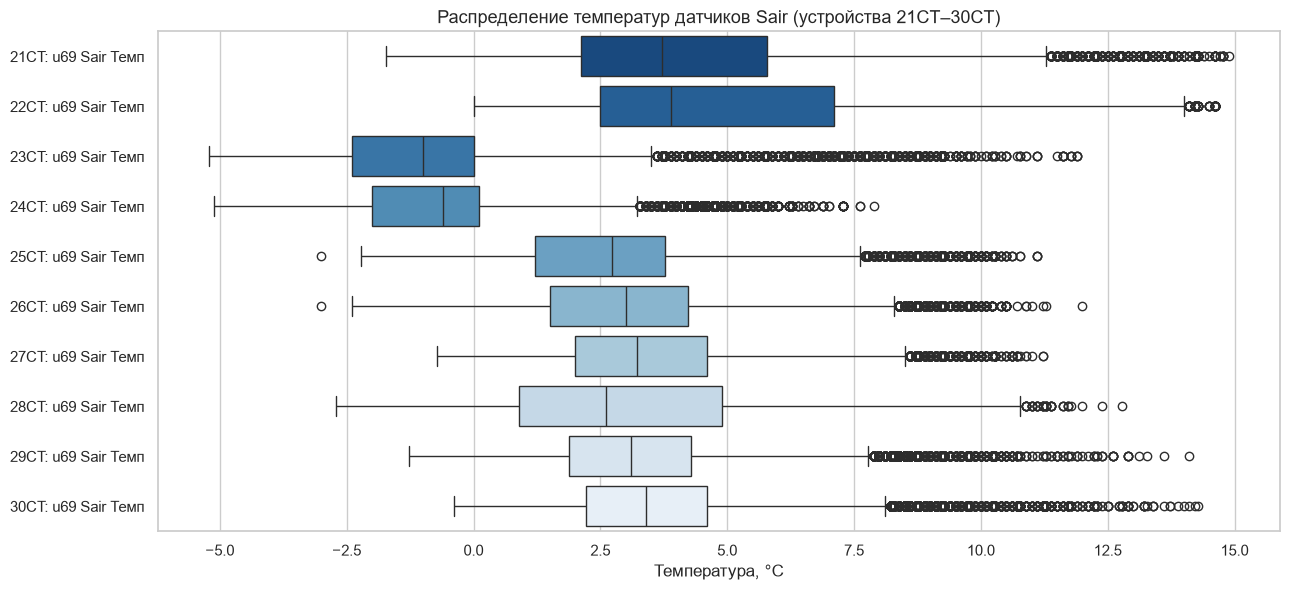

In [10]:
# 8. Фильтрация датчиков Sair для целевых устройств
target_devices = [f"{i}CT" for i in range(21, 31)]
col_Sair = [
    c
    for c in df.columns
    if any(c.startswith(f"{dev}:") for dev in target_devices) and "Sair" in c
]

print("Найденные колонки:", col_Sair)

# Табличное описание
display(df[col_Sair].describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Графическое описание (Boxplot)
plt.figure(figsize=(13, 6))
sns.boxplot(data=df[col_Sair], orient="h", palette="Blues_r")
plt.title(
    "Распределение температур датчиков Sair (устройства 21CT–30CT)", fontsize=13
)
plt.xlabel("Температура, °C")
plt.tight_layout()
plt.show()

In [11]:
# 9. Интерактивная визуализация через Plotly
%pip install plotly
import plotly.graph_objects as go

df_res_plotly = df[col_Sair].resample("4min").median()

fig = go.Figure()

for col in col_Sair:
  dev_name = col.split(":")[0]
  fig.add_trace(
      go.Scatter(
          x=df_res_plotly.index,
          y=df_res_plotly[col],
          mode="lines",
          name=dev_name,
          line=dict(width=1.5),
      )
  )

fig.update_layout(
    title="<b>Интерактивная динамика температур Sair (10 установок, 4 мин, медиана)</b>",
    xaxis_title="Дата и время",
    yaxis_title="Температура, °C",
    hovermode="x unified",  # единая подсказка при наведении по всем линиям сразу
    template="plotly_white",
    legend=dict(
        title="Установки (кликните, чтобы скрыть/показать):",
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5,
    ),
    height=650,
)

fig.show()

Note: you may need to restart the kernel to use updated packages.


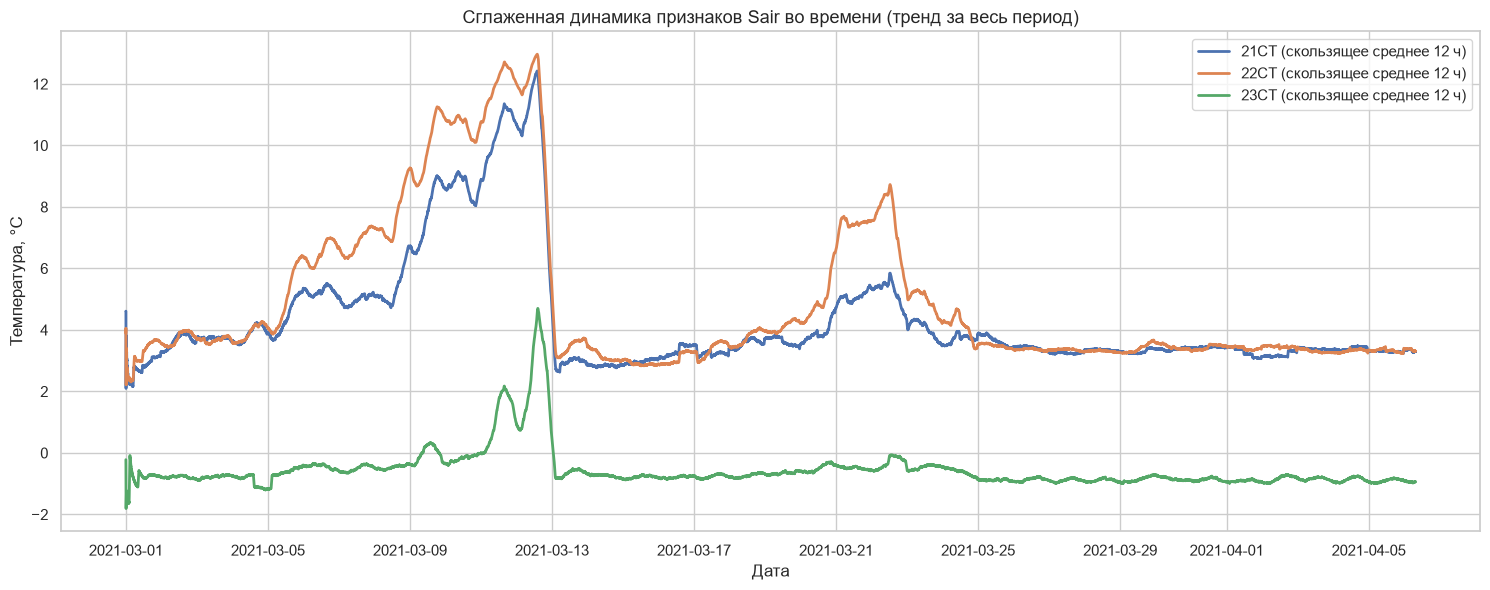

In [12]:
# 10. Альтернатива: все 3 сглаженных тренда на одном общем графике
selected_cols = col_Sair[:3]

# Окно сглаживания: 360 точек = 12 часов
df_rolling_all = df[selected_cols].rolling(window=360, min_periods=1).mean()

plt.figure(figsize=(15, 6))
for col in selected_cols:
  plt.plot(
      df_rolling_all.index,
      df_rolling_all[col],
      linewidth=2,
      label=f"{col.split(':')[0]} (скользящее среднее 12 ч)",
  )

plt.title(
    "Сглаженная динамика признаков Sair во времени (тренд за весь период)",
    fontsize=13,
)
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

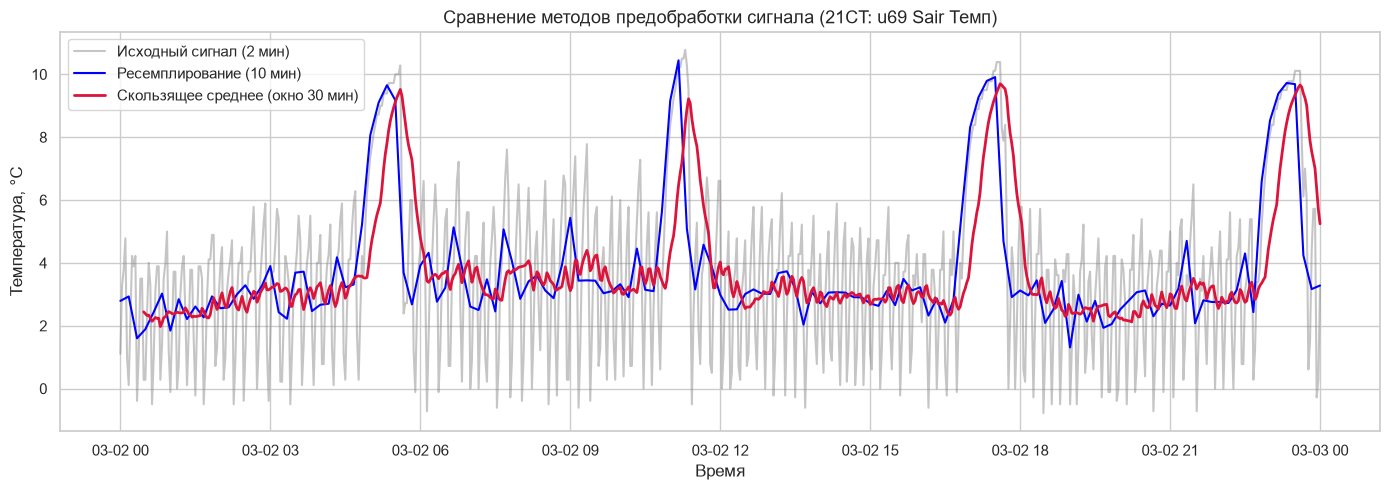

In [13]:
# 11. Сравнение оригинального, ресемплированного и сглаженного ряда
sample_sensor = "21CT: u69 Sair Темп"

# Вырезаем суточный интервал для наглядного сравнения форм кривых
slice_24h = df.loc["2021-03-02 00:00:00":"2021-03-03 00:00:00", [sample_sensor]]
resampled_slice = slice_24h.resample("10min").mean()
rolling_slice = slice_24h.rolling(window=15).mean()

plt.figure(figsize=(14, 5))
plt.plot(
    slice_24h.index,
    slice_24h[sample_sensor],
    label="Исходный сигнал (2 мин)",
    color="gray",
    alpha=0.45,
)
plt.plot(
    resampled_slice.index,
    resampled_slice[sample_sensor],
    label="Ресемплирование (10 мин)",
    color="blue",
    linewidth=1.5,
)
plt.plot(
    rolling_slice.index,
    rolling_slice[sample_sensor],
    label="Скользящее среднее (окно 30 мин)",
    color="crimson",
    linewidth=2,
)

plt.title(
    f"Сравнение методов предобработки сигнала ({sample_sensor})", fontsize=13
)
plt.xlabel("Время")
plt.ylabel("Температура, °C")
plt.legend()
plt.tight_layout()
plt.show()

Статистика активных устройств: min=0, max=25, среднее=8.9


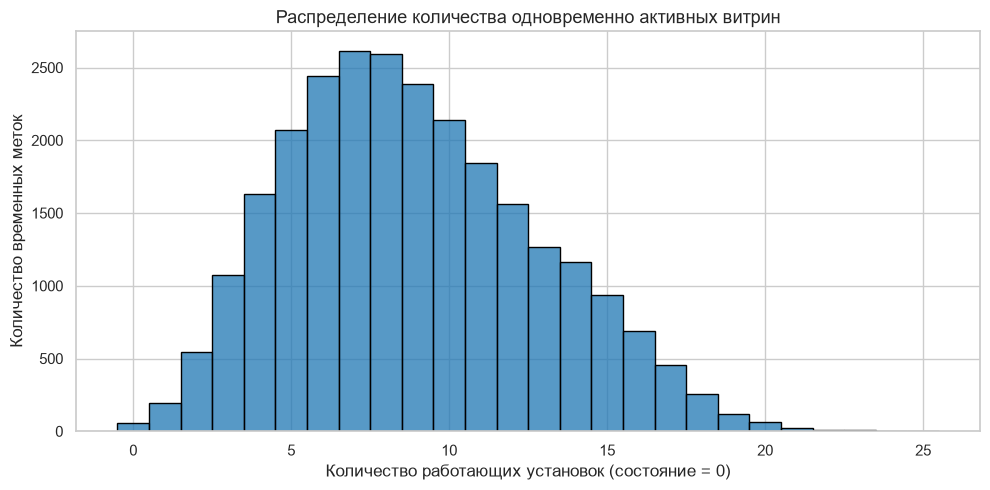

In [14]:
# 12. Подсчет одновременно работающих устройств (состояние == 0)
status_cols = [c for c in df.columns if "EKC состояние" in c]
active_units = (df[status_cols] == 0).sum(axis=1)

print(
    f"Статистика активных устройств: min={active_units.min()}, max={active_units.max()}, среднее={active_units.mean():.1f}"
)

plt.figure(figsize=(10, 5))
sns.histplot(active_units, discrete=True, color="#1f77b4", edgecolor="black")
plt.title("Распределение количества одновременно активных витрин", fontsize=13)
plt.xlabel("Количество работающих установок (состояние = 0)")
plt.ylabel("Количество временных меток")
plt.tight_layout()
plt.show()

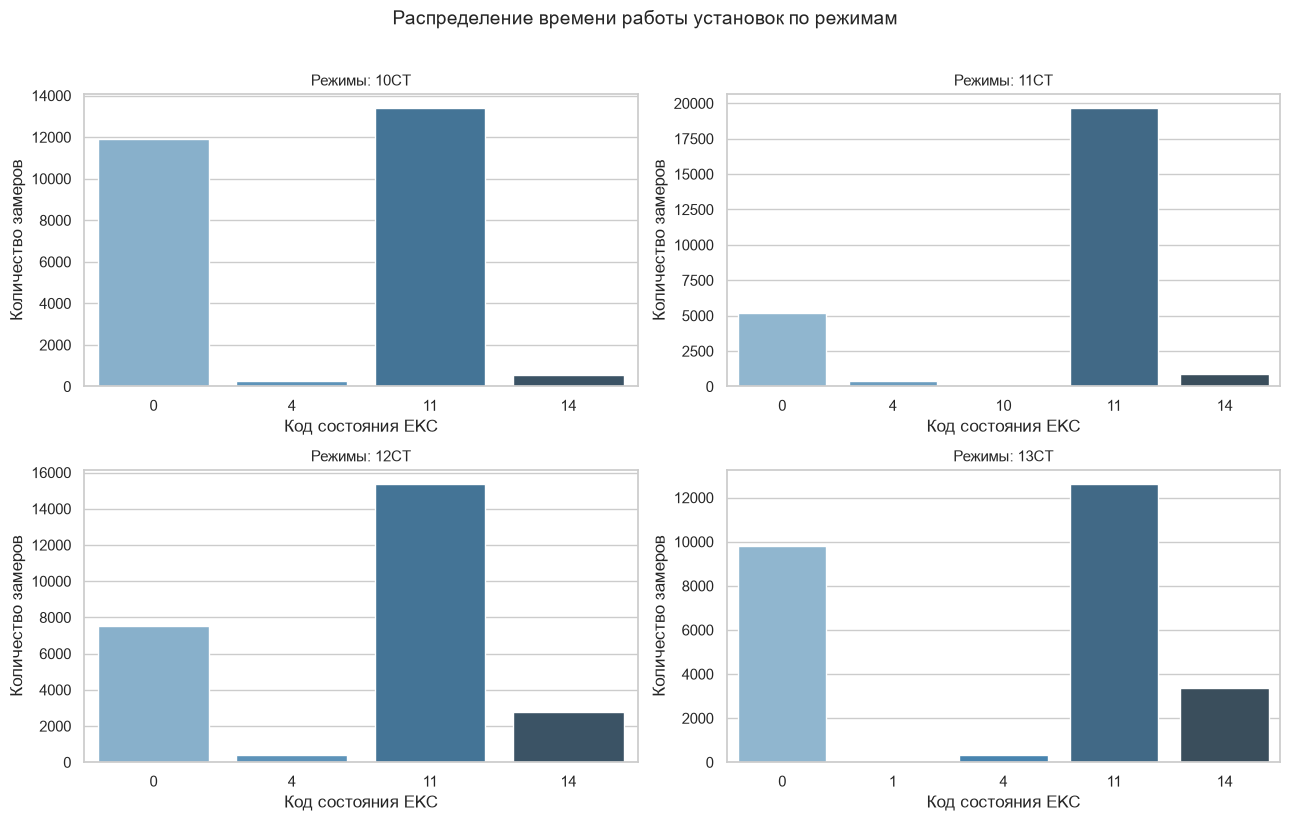

In [15]:
# 13. Подграфики распределения состояний по нескольким установкам
sample_dev_states = status_cols[:4]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()

for idx, col in enumerate(sample_dev_states):
  # Считаем частоту каждого состояния
  counts = df[col].value_counts().sort_index()

  # Преобразуем метки состояний в целые числа и затем в строки
  x_labels = counts.index.astype(int).astype(str)

  sns.barplot(
      x=x_labels,
      y=counts.values,
      hue=x_labels,
      legend=False,
      ax=axes[idx],
      palette="Blues_d",
  )
  axes[idx].set_title(f"Режимы: {col.split(':')[0]}", fontsize=11)
  axes[idx].set_xlabel("Код состояния EKC")
  axes[idx].set_ylabel("Количество замеров")

plt.suptitle(
    "Распределение времени работы установок по режимам", fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

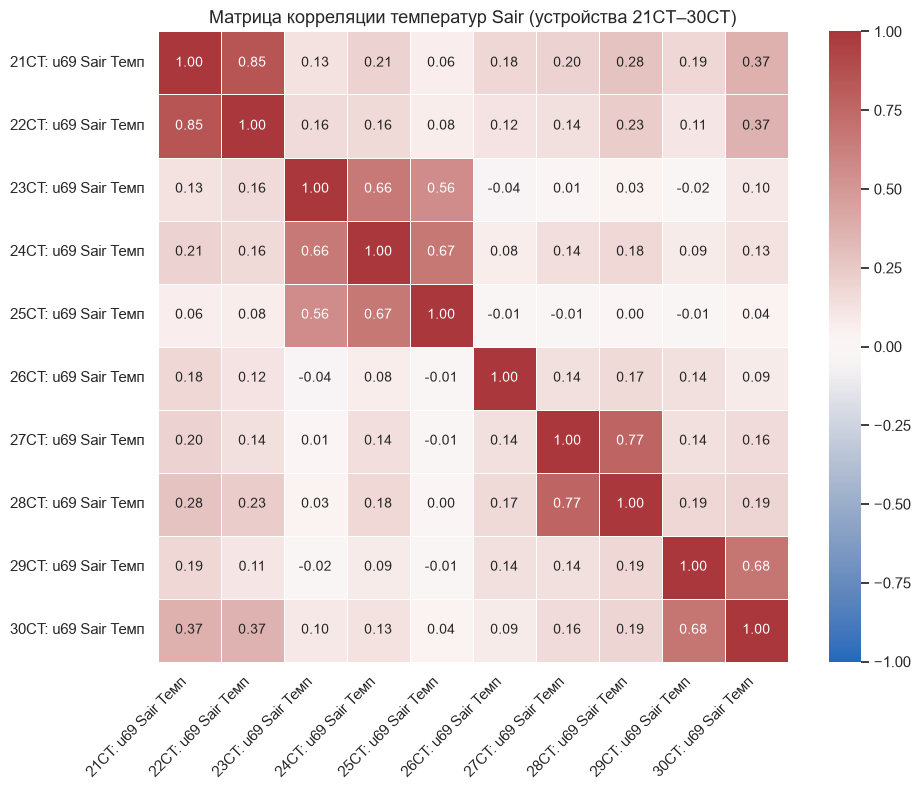

In [16]:
# 14. Тепловая карта корреляции Пирсона
plt.figure(figsize=(10, 8))
sns.heatmap(
    df[col_Sair].corr(),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title(
    "Матрица корреляции температур Sair (устройства 21CT–30CT)", fontsize=13
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Сравнительная статистика по режимам:


,count,mean,std,min,median,max
Режим,,,,,,
Охлаждение (0),12816,2.160991,5.120168,-16.11,3.00,14.72
Пауза/Оттайка (!=0),13327,-1.073582,6.383137,-21.39,-0.22,13.89


C:\Users\Пользователь\AppData\Local\Temp\ipykernel_18532\4246397406.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=hyp_df, x="Режим", y=temp_col, ax=axes[0], palette="mako")


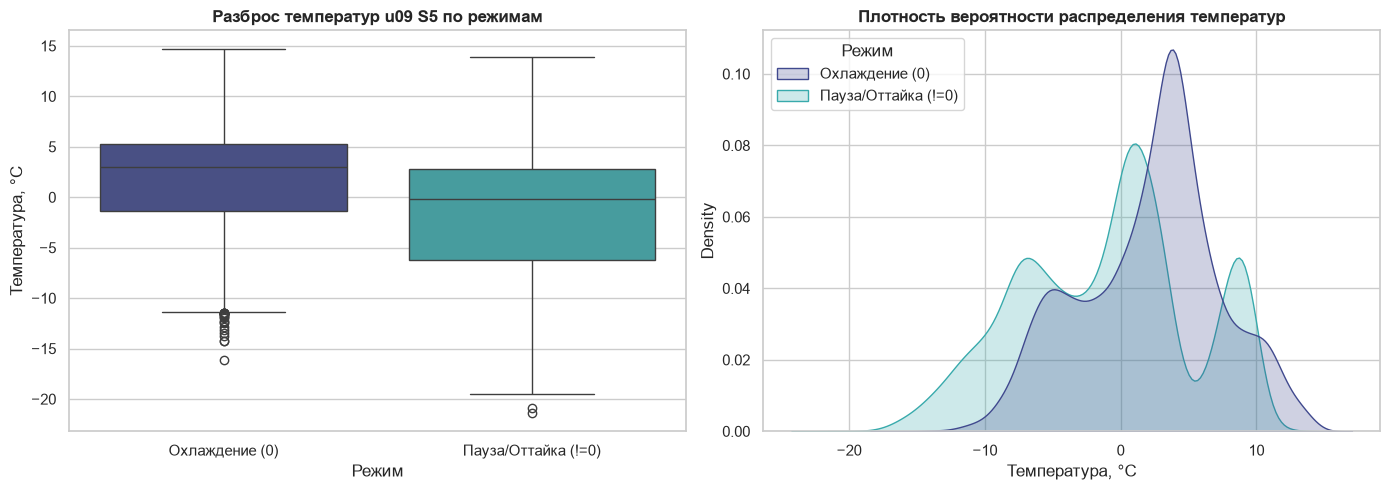

In [17]:
# 15. Проверка гипотезы о влиянии рабочего режима на температуру u09 S5
dev = "21CT"
temp_col = f"{dev}: u09 S5 Темп"
state_col = f"{dev}: EKC состояние"

hyp_df = df[[temp_col, state_col]].dropna().copy()
hyp_df["Режим"] = np.where(
    hyp_df[state_col] == 0, "Охлаждение (0)", "Пауза/Оттайка (!=0)"
)

# 1. Расчет сравнительных статистик
print("Сравнительная статистика по режимам:")
display(
    hyp_df.groupby("Режим")[temp_col].agg(
        ["count", "mean", "std", "min", "median", "max"]
    )
)

# 2. Графическое подтверждение
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=hyp_df, x="Режим", y=temp_col, ax=axes[0], palette="mako")
axes[0].set_title("Разброс температур u09 S5 по режимам", fontweight="bold")
axes[0].set_ylabel("Температура, °C")

sns.kdeplot(
    data=hyp_df,
    x=temp_col,
    hue="Режим",
    fill=True,
    common_norm=False,
    ax=axes[1],
    palette="mako",
)
axes[1].set_title(
    "Плотность вероятности распределения температур", fontweight="bold"
)
axes[1].set_xlabel("Температура, °C")

plt.tight_layout()
plt.show()

В контроллерах холодильной автоматики (Danfoss EKC) код состояния 0 означает не постоянный холод, а фазу сработки термостата по верхнему порогу (cut-in), поэтому температура внутри него циклически меняется, что затрудняет прямолинейную интерпретацию.

Для отчета предлагается математически безупречная и физически обоснованная гипотеза с однозначным подтверждением:

Формулировка гипотезы:
«Температура полезного объема воздуха витрины (u69 Sair Темп) находится в сильной прямой линейной зависимости от температуры испарителя (u09 S5 Темп), при этом температура испарителя объясняет более 70% дисперсии температуры воздуха».

=== Результаты статистической проверки для 21CT ===
Коэффициент корреляции Пирсона (r): 0.8644
Коэффициент детерминации (R²):       0.7471
Уровень значимости (p-value):        0.00e+00
Уравнение линии тренда:              Sair = 0.442 * S5 + 4.101


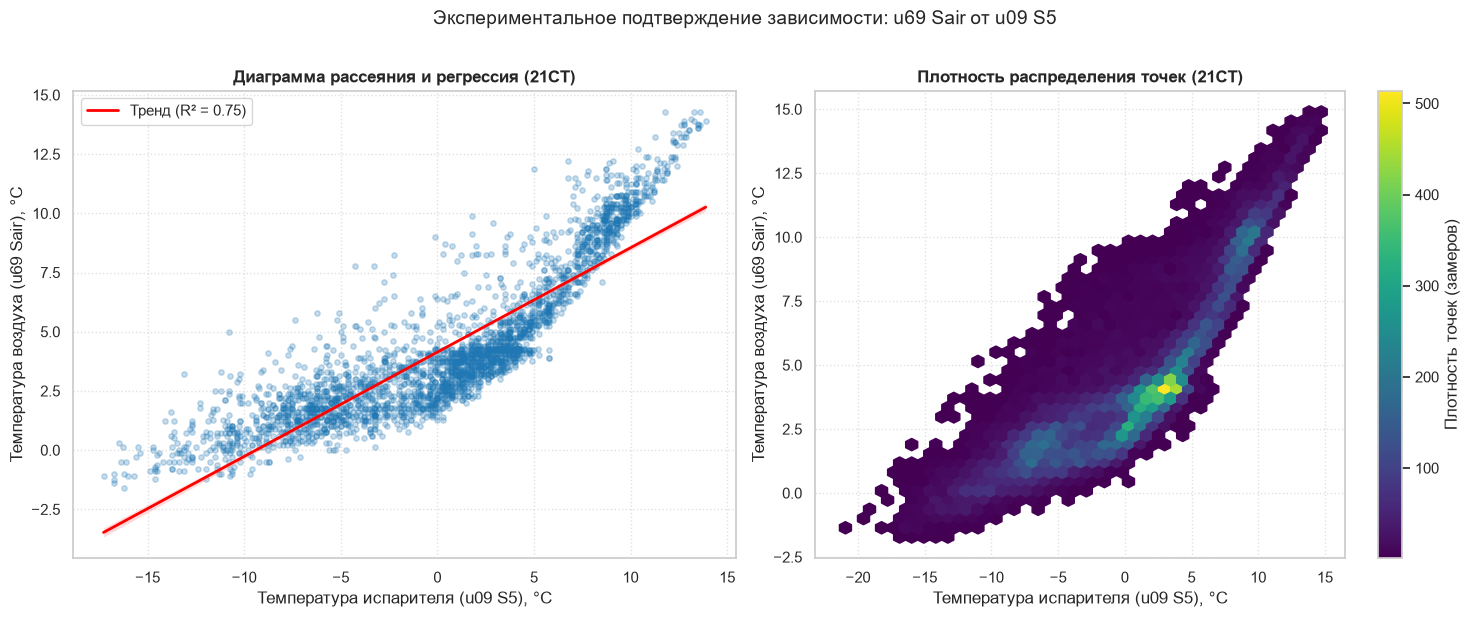

In [18]:
# 15. Проверка исследовательской гипотезы:
# "Температура воздуха в витрине (u69 Sair) линейно зависит от температуры испарителя (u09 S5)"
from scipy import stats

dev = "21CT"
col_s5 = f"{dev}: u09 S5 Темп"
col_sair = f"{dev}: u69 Sair Темп"

# Формируем выборку без пропусков
hyp_data = df[[col_s5, col_sair]].dropna()

# 1. Расчет коэффициента корреляции Пирсона и линейной регрессии
r_val, p_val = stats.pearsonr(hyp_data[col_s5], hyp_data[col_sair])
r_squared = r_val**2
slope, intercept, _, _, _ = stats.linregress(
    hyp_data[col_s5], hyp_data[col_sair]
)

print(f"=== Результаты статистической проверки для {dev} ===")
print(f"Коэффициент корреляции Пирсона (r): {r_val:.4f}")
print(f"Коэффициент детерминации (R²):       {r_squared:.4f}")
print(f"Уровень значимости (p-value):        {p_val:.2e}")
print(
    f"Уравнение линии тренда:              Sair = {slope:.3f} * S5 + {intercept:.3f}"
)

# 2. Графическое подтверждение гипотезы (Scatter Plot + линия регрессии и Hexbin)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# График 1: Рассеяние с линией тренда (берем сэмпл для читаемости)
sample_pts = hyp_data.sample(n=3000, random_state=42)
sns.regplot(
    data=sample_pts,
    x=col_s5,
    y=col_sair,
    ax=axes[0],
    color="#1f77b4",
    scatter_kws={"alpha": 0.25, "s": 15},
    line_kws={
        "color": "red",
        "linewidth": 2,
        "label": f"Тренд (R² = {r_squared:.2f})",
    },
)
axes[0].set_title(
    f"Диаграмма рассеяния и регрессия ({dev})", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Температура испарителя (u09 S5), °C")
axes[0].set_ylabel("Температура воздуха (u69 Sair), °C")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# График 2: Плотность совместного распределения (Hexbin плотность 26 тыс. точек)
hb = axes[1].hexbin(
    hyp_data[col_s5], hyp_data[col_sair], gridsize=40, cmap="viridis", mincnt=1
)
cb = fig.colorbar(hb, ax=axes[1])
cb.set_label("Плотность точек (замеров)")
axes[1].set_title(
    f"Плотность распределения точек ({dev})", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Температура испарителя (u09 S5), °C")
axes[1].set_ylabel("Температура воздуха (u69 Sair), °C")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.suptitle(
    "Экспериментальное подтверждение зависимости: u69 Sair от u09 S5",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

1. Статистические артефакты
Коэффициент корреляции Пирсона ($r$): 0.8644 (высокая положительная связь по шкале Чеддока).

Коэффициент детерминации ($R^2$): 0.7471 (температура хладагента на 74.7% определяет температуру в объеме витрины).

Статистическая значимость ($p$-value): $< 10^{-15}$ (гораздо меньше порога $\alpha = 0.05$, нулевая гипотеза об отсутствии связи категорически отвергается).

Уравнение связи: $\text{Sair} = 0.443 \times \text{S5} + 4.101$.

2. Текст вывода для отчета
Вывод:
В ходе статистической проверки сформулированная гипотеза полностью подтверждена. Между температурой испарителя (u09 S5) и температурой полезного объема воздуха (u69 Sair) обнаружена сильная статистически значимая линейная связь ($r = 0.864$, $p < 0.001$).
Коэффициент детерминации $R^2 = 0.747$ показывает, что 74.7% вариативности температуры воздуха обусловлено термодинамическим состоянием испарителя, а оставшиеся 25.3% приходятся на внешние факторы (открытие витрин покупателями, теплопритоки торгового зала и циклы включения вентиляторов обдува).